<a href="https://colab.research.google.com/github/mevalle/v-nets/blob/main/Ghost%20Features%20and%20Spooky%20Transfer%20Learning%20(Example%20with%20BloodMNIST).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Ghost Features and Spooky Transfer Learning for Hypercomplex-Valued Neural Networks

This Jupyter Notebook illustrates the extraction of Ghost Features and the concept of Spooky Transfer Learning, as described in the paper "Ghost Features and Spooky Transfer Learning for Hypercomplex-Valued Neural Networks," which has been accepted for presentation at the 2026 IEEE International Workshop on Machine Learning for Signal Processing (MLSP 2026).

The experimental evaluation uses BloodMNIST for illustrative and reproducibility purposes. You should be able to run the entire notebook in Colab using a GPU. Please note, however, that the results presented in this notebook may differ slightly from those reported in the paper because we reduced the number of simulations and epochs to make it easier and quicker for you to execute. Enjoy your exploration!

# Load Libraries

Load the basic libraries, includinv V-Nets.py.

In [1]:
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow.keras as kr
import matplotlib.pyplot as plt

from tensorflow.keras.applications import EfficientNetV2B0

from tensorflow.keras.layers import Input, Dense, Conv2D, Dropout, Layer

In [2]:
!wget -q https://raw.githubusercontent.com/mevalle/v-nets/main/V_Nets.py

from V_Nets import V_Dense, V_Conv2D, get_algebra

# Load the dataset

In [3]:
!pip install medmnist

from medmnist import BloodMNIST

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.9 MB/s eta 0:00:00


In [4]:
im_size = 224

train_dataset = BloodMNIST(split='train', download=True, as_rgb=True, size=im_size)
x_train, y_train = train_dataset.imgs, train_dataset.labels

test_dataset = BloodMNIST(split='test', download=True, as_rgb=True, size=im_size)
x_test, y_test = test_dataset.imgs, test_dataset.labels

print("Training dataset loaded:", train_dataset)
print("Test dataset loaded:", test_dataset)

100%|██████████| 1.54G/1.54G [06:55<00:00, 3.70MB/s]


Training dataset loaded: Dataset BloodMNIST of size 224 (bloodmnist_224)
    Number of datapoints: 11959
    Root location: /root/.medmnist
    Split: train
    Task: multi-class
    Number of channels: 3
    Meaning of labels: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}
    Number of samples: {'train': 11959, 'val': 1712, 'test': 3421}
    Description: The BloodMNIST is based on a dataset of individual normal cells, captured from individuals without infection, hematologic or oncologic disease and free of any pharmacologic treatment at the moment of blood collection. It contains a total of 17,092 images and is organized into 8 classes. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images with resolution 3×360×363 pixels are center-cropped into 3×200×200, and then resized i

In [5]:
y_train_oh = tf.keras.utils.to_categorical(y_train.flatten(), num_classes=8)
y_test_oh = tf.keras.utils.to_categorical(y_test.flatten(), num_classes=8)

Show some images!

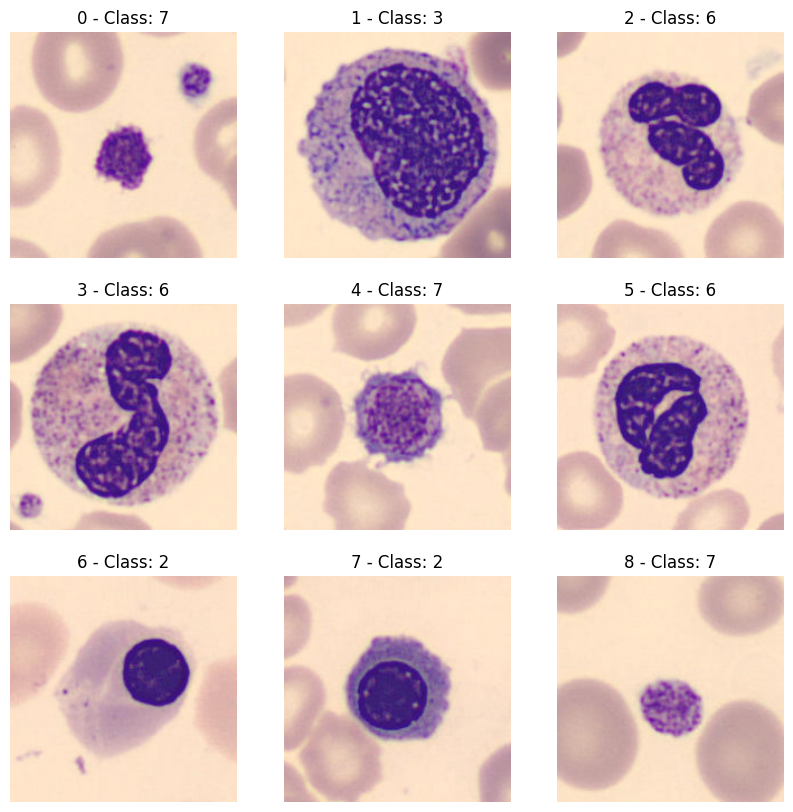

In [6]:
# Take one batch (16 images if that was your batch_size)
plt.figure(figsize=(10, 10))
for i in range(9):
    image = x_train[i]
    label = y_train[i][0]
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(image.astype("int32"))
    plt.title(f"{i} - Class: {int(label)}")
    plt.axis("off")

# Quaternionify layer and data augmentation

In [7]:
class Quaternionify(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
    def call(self, inputs):
      # Create a tensor of zeros for the new channel
      # The shape will be (batch_size, height, width, 1)
      input_shape = tf.shape(inputs)
      zeros_channel = tf.zeros((input_shape[0], input_shape[1], input_shape[2], 1), dtype=inputs.dtype)

      # Concatenate the original preprocessed image with the zeros channel along the last axis (channels)
      return tf.concat([zeros_channel, inputs], axis=-1)

In [8]:
data_augmentation = kr.Sequential(
  [
    # kr.layers.RandomZoom(height_factor=(-0.3,0.0), width_factor=None),
    kr.layers.RandomFlip("horizontal_and_vertical"),
    kr.layers.RandomRotation(0.5),
  ]
)

Show some augmented images:

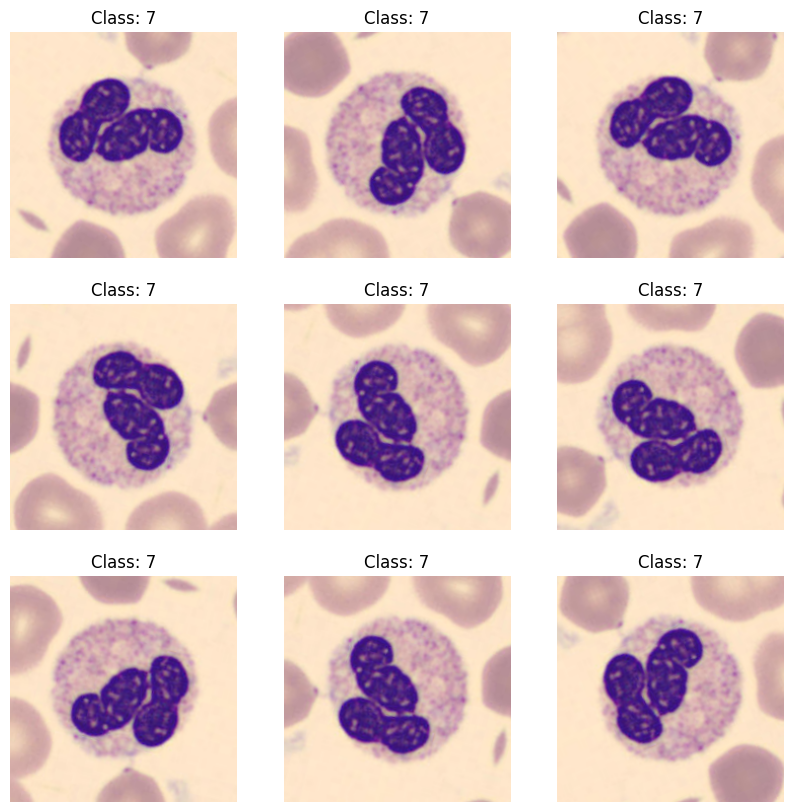

In [9]:
plt.figure(figsize=(10, 10))
img = x_train[2]
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  augmented_image = data_augmentation(
    tf.expand_dims(img, 0), training=True
  )
  plt.imshow(augmented_image[0].numpy().astype("int32"))
  plt.title(f"Class: {int(y_train[0][0])}")
  plt.axis("off")

# Load and test the pre-trained EfficientNetB0 model

## Simulation parameters

In [10]:
Nsim = 2  # We used Nsim = 10 in the paper, which requires more time!
NEpochs = 10  # We used NEpochs = 15 in the paper, which also requires more time!

## Load the model

In [11]:
kr.backend.clear_session()

base_model = EfficientNetV2B0(include_top=False,
                              weights="imagenet",
                              pooling='avg',
                              input_shape=(224, 224, 3))
base_model.trainable = False
# base_model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [12]:
# Create a sub-model that only contains that "tail" section
last_base_layers = kr.Model(inputs=base_model.layers[4].input, outputs=base_model.layers[-1].output)
# last_base_layers.summary()

## Fine-tune and test the traditional model

In [13]:
accuracy_effnet = []
hist_effnet = []
for s in range(Nsim):
    print("Simulation",s+1,"of",Nsim)

    # Build the model
    kr.backend.clear_session()
    effnet = kr.Sequential(
                    [
                        Input(shape=(224,224,3)),
                        data_augmentation,
                        base_model.layers[1],
                        base_model.layers[2],
                        base_model.layers[3],
                        last_base_layers,
                        Dropout(0.2), # Standard dropout rate for V2-B0
                        Dense(8,activation='softmax'),
                    ])

    effnet.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"]
              )

    # Train the model
    hist = effnet.fit(x = x_train, y = y_train,
      validation_data=(x_test,y_test),
      epochs = NEpochs, verbose=1)
    hist_effnet.append(hist)

    # Evaluate the model
    test_loss, test_acc = effnet.evaluate(x = x_test, y = y_test, verbose=1)
    accuracy_effnet.append(test_acc)
    print('Test accuracy:', test_acc)

    df_accuracy_effnet = pd.DataFrame({'accuracy_effnet': accuracy_effnet})
    df_accuracy_effnet.to_csv('accuracy_effnet.csv', index=False)


# Save the history
hist_data = [h.history for h in hist_effnet]
with open('hist_effnet.json', 'w') as f:
    json.dump(hist_data, f)

print("History saved as 'hist_effnet.json'")

Simulation 1 of 2
Epoch 1/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 51s 91ms/step - accuracy: 0.7372 - loss: 0.8679 - val_accuracy: 0.8755 - val_loss: 0.4880
Epoch 2/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 29s 78ms/step - accuracy: 0.8688 - loss: 0.4681 - val_accuracy: 0.9035 - val_loss: 0.3544
Epoch 3/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 29s 76ms/step - accuracy: 0.8893 - loss: 0.3787 - val_accuracy: 0.9222 - val_loss: 0.2815
Epoch 4/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 29s 77ms/step - accuracy: 0.9035 - loss: 0.3338 - val_accuracy: 0.9328 - val_loss: 0.2453
Epoch 5/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 29s 77ms/step - accuracy: 0.9061 - loss: 0.3069 - val_accuracy: 0.9383 - val_loss: 0.2238
Epoch 6/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 29s 77ms/step - accuracy: 0.9114 - loss: 0.2864 - val_accuracy: 0.9357 - val_loss: 0.2122
Epoch 7/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 29s 78ms/step - accuracy: 0.9170 - loss: 0.2646 - val_accuracy: 0.9480 - val_loss: 0.1930
Epoch 8/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 45s 90ms/step - accuracy: 0.9193

# Spooky Transfer Learning

Embed the weights of the first convolution into a V_Conv2D layer with ghost features!

In [14]:
# Get the weights of the first convolutional layer
W = base_model.layers[3].weights[0]

# Assuming W is already a tf.Tensor or can be converted to one
W_shape = W.shape

# Create a tensor of zeros with the same kernel dimensions and output filters, but 1 input channel
zeros_channel_weights = tf.zeros(W_shape[:-2] + (1, W_shape[-1]), dtype=W.dtype)

# Concatenate W with the zeros tensor along the third axis (index 2)
W_quat = tf.concat([zeros_channel_weights, -W], axis=2)

# Reshape the tensor by informing there is one quaternion input channel with the real and imaginary parts in the last dimension.
W_quat = tf.expand_dims(W_quat, axis=-1)
W_quat = tf.transpose(W_quat, perm=[0, 1, 4, 3, 2])

print(f"Original W shape: {W_shape}")
print(f"W_quat shape: {W_quat.shape}")

Original W shape: (3, 3, 3, 32)
W_quat shape: (3, 3, 1, 32, 4)


In [15]:
V_conv_layer = V_Conv2D(32,
                        kernel_size=base_model.layers[3].get_config()['kernel_size'],
                        strides=base_model.layers[3].get_config()['strides'],
                        padding=base_model.layers[3].get_config()['padding'],
                        use_bias=base_model.layers[3].get_config()['use_bias'],
                        activation=base_model.layers[3].get_config()['activation'],
                        algebra = get_algebra("quaternion"),
)

Layers to reduce dimension

In [16]:
V_Reduce_Features = V_Conv2D(8,
                        kernel_size=(1,1),
                        strides=(1,1),
                        padding='valid',
                        use_bias=False,
                        activation=None,
                        algebra = get_algebra("quaternion"),
)


Reduce_Features = Conv2D(32,
                        kernel_size=(1,1),
                        strides=(1,1),
                        padding='valid',
                        use_bias=False,
                        activation=None,
)

## Example of ghost features

In [17]:
x = x_train[94]

# Expand the dimension;
x_ghost = tf.expand_dims(x, axis=0)

# Apply the first layers of the EfficientNet model
x_ghost = base_model.layers[1](x_ghost)
x_ghost = base_model.layers[2](x_ghost)
# Convert the inputs to quaternions
x_ghost = Quaternionify()(x_ghost)
# Compute the ghost features
x_ghost = V_conv_layer(x_ghost)

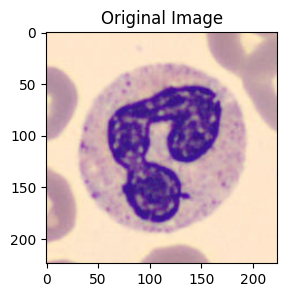

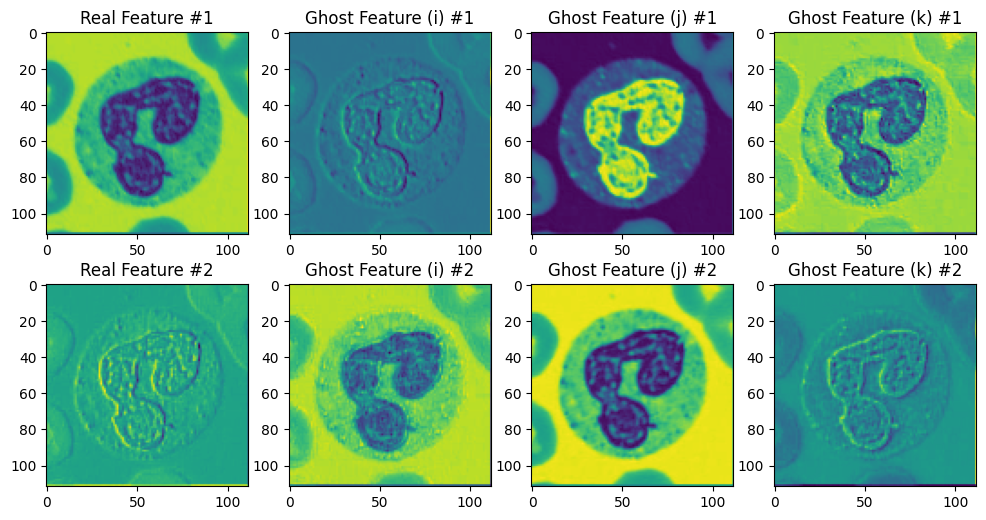

In [18]:
plt.figure(figsize=(3, 3))
plt.imshow(x)
plt.title("Original Image")
plt.show()

plt.figure(figsize=(12, 6))

for i in range(2):
  plt.subplot(2,4,1+4*i)
  plt.imshow(x_ghost[0,:,:,i])
  plt.title(f"Real Feature #{i+1}")

  plt.subplot(2,4,2+4*i)
  plt.imshow(x_ghost[0,:,:,i+32])
  plt.title(f"Ghost Feature (i) #{i+1}")

  plt.subplot(2,4,3+4*i)
  plt.imshow(x_ghost[0,:,:,i+64])
  plt.title(f"Ghost Feature (j) #{i+1}")

  plt.subplot(2,4,4+4*i)
  plt.imshow(x_ghost[0,:,:,i+96])
  plt.title(f"Ghost Feature (k) #{i+1}")

plt.show()

## Spooky Transfer Learning (Vector-valued Dimension Reduction)

In [19]:
accuracy_spookyV = []
hist_spookyV = []
for s in range(Nsim):
    print("Simulation",s+1,"of",Nsim)

    # Build the model
    kr.backend.clear_session()
    inputs = Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = base_model.layers[1](x)
    x = base_model.layers[2](x)
    # Convert the inputs to quaternions
    x = Quaternionify()(x)
    # Compute the ghost features
    x = V_conv_layer(x)
    # Reduce dimension
    x = V_Reduce_Features(x)

    # Now, feed this into the rest of the base_model (from layer 3 onwards)
    x = last_base_layers(x)

    # Add the final classification layers
    final_output = Dropout(0.2)(x)
    predictions = kr.layers.Dense(8, activation='softmax')(final_output)

    spookyV_effnet = kr.Model(inputs=inputs, outputs=predictions, name="spooky_effnet")

    # Freeze the weights of the first V-Conv2d
    spookyV_effnet.layers[5].set_weights([W_quat])
    spookyV_effnet.layers[5].trainable = False

    spookyV_effnet.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"]
              )

    # Train the model
    hist = spookyV_effnet.fit(x = x_train, y = y_train, validation_data=(x_test,y_test), epochs = NEpochs, verbose=1)
    hist_spookyV.append(hist)

    # Evaluate the model
    test_loss, test_acc = spookyV_effnet.evaluate(x = x_train, y = y_train, verbose=1)
    accuracy_spookyV.append(test_acc)
    print('Test accuracy:', test_acc)

    df_accuracy_spookyV = pd.DataFrame({'accuracy_spookyV': accuracy_spookyV})
    df_accuracy_spookyV.to_csv('accuracy_spookyV.csv', index=False)


# Save the history
hist_data = [h.history for h in hist_spookyV]
with open('hist_spookyV.json', 'w') as f:
    json.dump(hist_data, f)

print("History saved as 'hist_spookyV.json'")

Simulation 1 of 2
Epoch 1/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 78s 171ms/step - accuracy: 0.7950 - loss: 0.6473 - val_accuracy: 0.9199 - val_loss: 0.2749
Epoch 2/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 158ms/step - accuracy: 0.9084 - loss: 0.2834 - val_accuracy: 0.9468 - val_loss: 0.1824
Epoch 3/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.9283 - loss: 0.2210 - val_accuracy: 0.9538 - val_loss: 0.1527
Epoch 4/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 158ms/step - accuracy: 0.9333 - loss: 0.1991 - val_accuracy: 0.9602 - val_loss: 0.1267
Epoch 5/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.9408 - loss: 0.1741 - val_accuracy: 0.9673 - val_loss: 0.1145
Epoch 6/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.9442 - loss: 0.1622 - val_accuracy: 0.9620 - val_loss: 0.1203
Epoch 7/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.9472 - loss: 0.1536 - val_accuracy: 0.9699 - val_loss: 0.0975
Epoch 8/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy

## Spooky Transfer Learning (Real-valued Dimension Reduction)

In [20]:
accuracy_spookyR = []
hist_spookyR = []
for s in range(Nsim):
    print("Simulation",s+1,"of",Nsim)

    # Build the model
    kr.backend.clear_session()
    inputs = Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = base_model.layers[1](x)
    x = base_model.layers[2](x)
    # Convert the inputs to quaternions
    x = Quaternionify()(x)
    # Compute the ghost features
    x = V_conv_layer(x)
    # Reduce dimension
    x = Reduce_Features(x)

    # Now, feed this into the rest of the base_model (from layer 3 onwards)
    x = last_base_layers(x)

    # Add the final classification layers
    final_output = Dropout(0.2)(x)
    predictions = kr.layers.Dense(8, activation='softmax')(final_output)

    spookyR_effnet = kr.Model(inputs=inputs, outputs=predictions, name="spooky_effnet")

    # Freeze the weights of the first V-Conv2d
    spookyR_effnet.layers[5].set_weights([W_quat])
    spookyR_effnet.layers[5].trainable = False

    spookyR_effnet.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"]
              )

    # Train the model
    hist = spookyR_effnet.fit(x = x_train, y = y_train, validation_data=(x_test,y_test), epochs = NEpochs, verbose=1)
    hist_spookyR.append(hist)

    # Evaluate the model
    test_loss, test_acc = spookyR_effnet.evaluate(x = x_train, y = y_train, verbose=1)
    accuracy_spookyR.append(test_acc)
    print('Test accuracy:', test_acc)

    df_accuracy_spookyR = pd.DataFrame({'accuracy_spookyR': accuracy_spookyR})
    df_accuracy_spookyR.to_csv('accuracy_spookyR.csv', index=False)


# Save the history
hist_data = [h.history for h in hist_spookyR]
with open('hist_spookyR.json', 'w') as f:
    json.dump(hist_data, f)

print("History saved as 'hist_spookyR.json'")


Simulation 1 of 2
Epoch 1/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 75s 168ms/step - accuracy: 0.8026 - loss: 0.6199 - val_accuracy: 0.9167 - val_loss: 0.2897
Epoch 2/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 58s 156ms/step - accuracy: 0.9020 - loss: 0.2972 - val_accuracy: 0.9386 - val_loss: 0.1897
Epoch 3/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.9229 - loss: 0.2261 - val_accuracy: 0.9500 - val_loss: 0.1474
Epoch 4/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 158ms/step - accuracy: 0.9382 - loss: 0.1811 - val_accuracy: 0.9626 - val_loss: 0.1256
Epoch 5/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 59s 157ms/step - accuracy: 0.9456 - loss: 0.1562 - val_accuracy: 0.9582 - val_loss: 0.1180
Epoch 6/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 58s 156ms/step - accuracy: 0.9561 - loss: 0.1335 - val_accuracy: 0.9719 - val_loss: 0.0916
Epoch 7/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 58s 156ms/step - accuracy: 0.9576 - loss: 0.1216 - val_accuracy: 0.9716 - val_loss: 0.0888
Epoch 8/10
374/374 ━━━━━━━━━━━━━━━━━━━━ 58s 156ms/step - accuracy

## Sumarize the results:

Just a heads-up! The results in this notebook are a bit different from what you’ll find in the paper. We reduced the number of simulations and epochs to make it easier and quicker for you to run.

In [21]:
print("Traditional model (EfficientNetV2-B0): Accuracy = {:.4f} ± {:.4f}".format(np.mean(accuracy_effnet), np.std(accuracy_effnet)))
print("Spooky model with V-Conv2D: Accuracy = {:.4f} ± {:.4f}".format(np.mean(accuracy_spookyV), np.std(accuracy_spookyV)))
print("Spooky model with regular Conv2D: Accuracy = {:.4f} ± {:.4f}".format(np.mean(accuracy_spookyR), np.std(accuracy_spookyR)))

Traditional model (EfficientNetV2-B0): Accuracy = 0.9556 ± 0.0023
Spooky model with V-Conv2D: Accuracy = 0.9717 ± 0.0041
Spooky model with regular Conv2D: Accuracy = 0.9778 ± 0.0029


In [22]:
# Open the file in read mode ('r')
with open('hist_effnet.json', 'r') as file:
    # Load the JSON data into a Python variable
    hist_effnet = json.load(file)

# Open the file in read mode ('r')
with open('hist_spookyR.json', 'r') as file:
    # Load the JSON data into a Python variable
    hist_spookyR = json.load(file)

# Open the file in read mode ('r')
with open('hist_spookyV.json', 'r') as file:
    # Load the JSON data into a Python variable
    hist_spookyV = json.load(file)

In [23]:
def plot_mean_std(data,label, color='blue'):
    # Calculate stats across the rows
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    x = np.arange(data.shape[1])+1

    # Create the plot
    plt.plot(x, mean, label=label, color=color)
    plt.fill_between(x, mean - std, mean + std, color = color, alpha=0.2)
    # Force the plot to start at 1 and end exactly at 15
    plt.xticks(x)
    plt.margins(x=0)

    plt.legend()

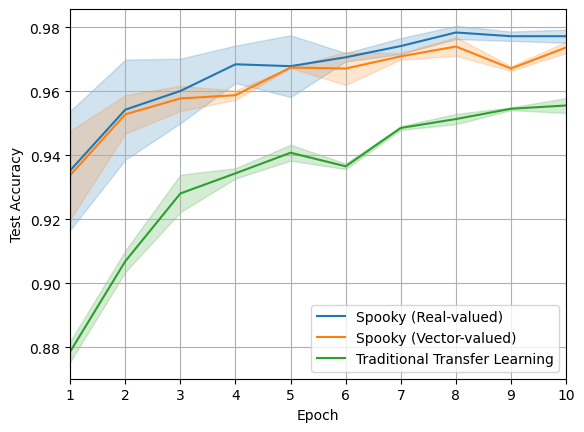

In [24]:
HspookyR = np.array([h['val_accuracy'] for h in hist_spookyR])
HspookyV = np.array([h['val_accuracy'] for h in hist_spookyV])
Heffnet = np.array([h['val_accuracy'] for h in hist_effnet])

plot_mean_std(HspookyR, label="Spooky (Real-valued)", color='tab:blue')
plot_mean_std(HspookyV, label="Spooky (Vector-valued)", color='tab:orange')
plot_mean_std(Heffnet, label="Traditional Transfer Learning", color='tab:green')
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.grid()

plt.savefig('BloodMNIST224_Accuracy_Curves.pdf', dpi=300, bbox_inches='tight')